# 01 · Data Understanding & Cleaning
**Dataset:** [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) — ~100k orders placed between 2016 and 2018 on the Olist marketplace.

**Goal of this notebook:** understand the 9 relational tables, measure data quality, clean them and build **one row per order** (`master_orders.parquet`) that all later steps use.

All cleaning logic lives in [`src/data_prep.py`](../src/data_prep.py) so it is reusable and testable; this notebook runs it and explains every step.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60); pd.set_option("display.float_format", "{:,.3f}".format)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)


## 1. The relational schema
```
customers ──< orders >── order_reviews
                │
                ├──< order_payments
                └──< order_items >── products ── category_translation
                          │
                          └── sellers
customers / sellers ── zip_code_prefix ── geolocation
```
`orders` is the hub table. One order can have several items (possibly from several sellers), several payments and (rarely) several reviews.

In [2]:
from src.data_prep import load_raw, quality_report, build_master
tables = load_raw()
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in tables.items()}).T

,rows,columns
customers,99441,5
geolocation,1000163,5
items,112650,7
payments,103886,5
reviews,99224,7
orders,99441,8
products,32951,9
sellers,3095,4
translation,71,2


In [3]:
for name in ["orders", "items", "products", "reviews"]:
    print(f"--- {name} ---"); display(tables[name].head(3))

--- orders ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


--- items ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.900,13.290
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.900,19.930
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.000,17.870


--- products ---


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.000,287.000,1.000,225.000,16.000,10.000,14.000
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.000,276.000,1.000,"1,000.000",30.000,18.000,20.000
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.000,250.000,1.000,154.000,18.000,9.000,15.000


--- reviews ---


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


## 2. Data-quality audit (before cleaning)

,table,column,missing,missing_pct
25,reviews,review_comment_title,87656,88.340
26,reviews,review_comment_message,58247,58.700
35,orders,order_delivered_customer_date,2965,2.980
39,products,product_name_lenght,610,1.850
38,products,product_category_name,610,1.850
40,products,product_description_lenght,610,1.850
41,products,product_photos_qty,610,1.850
34,orders,order_delivered_carrier_date,1783,1.790
33,orders,order_approved_at,160,0.160
42,products,product_weight_g,2,0.010


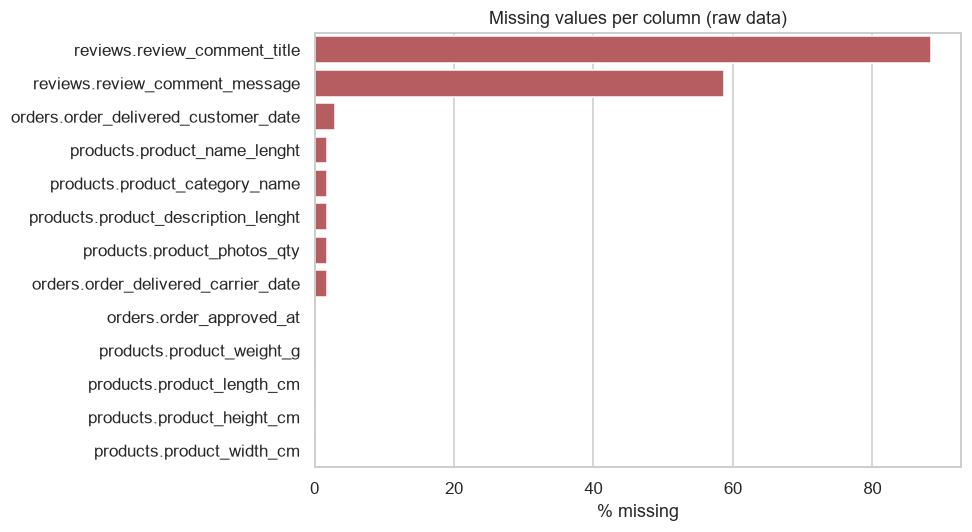

In [4]:
qr = quality_report(tables)
miss = qr[qr.missing > 0].sort_values("missing_pct", ascending=False)
display(miss[["table", "column", "missing", "missing_pct"]])
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=miss, y=miss.table + "." + miss.column, x="missing_pct", ax=ax, color="C3")
ax.set(xlabel="% missing", ylabel="", title="Missing values per column (raw data)")
plt.tight_layout(); plt.savefig(FIG / "missing_values.png"); plt.show()

In [5]:
print("Order status distribution:")
display(tables["orders"].order_status.value_counts().to_frame("orders"))
print("Duplicate rows per table:", {k: int(v.duplicated().sum()) for k, v in tables.items()})
print("Orders with >1 review:", int(tables["reviews"].order_id.duplicated().sum()))

Order status distribution:


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Duplicate rows per table: {'customers': 0, 'geolocation': 261831, 'items': 0, 'payments': 0, 'reviews': 0, 'orders': 0, 'products': 0, 'sellers': 0, 'translation': 0}
Orders with >1 review: 551


### Observations
* **Review comments** are missing for ~59% (title) / ~88% — customers often leave only a star rating. Not a problem: we only use the score + a `has_comment` flag.
* **Delivery timestamps** are missing for undelivered / canceled orders — expected, not an error.
* **Products** miss category for 610 products and dimensions for 2 → imputed.
* **Geolocation** has ~1M rows with many duplicates per zip prefix and a few points outside Brazil.
* Some orders have more than one review → keep the latest.

## 3. Cleaning & aggregation steps
| Table | Action | Why |
|---|---|---|
| products | translate category to English, missing → `unknown`, impute dimensions/weight by category median | keep all products, sensible values |
| items | aggregate per order: n_items, n_sellers, total price & freight, total weight; **main item** = most expensive item → category, seller | model works at order level |
| payments | drop `not_defined`; total value, max installments, main payment type, voucher flag | one row per order |
| reviews | keep latest review per order; `bad_review = score ≤ 3` | one label per order |
| geolocation | drop points outside Brazil, median lat/lng per zip prefix → **haversine distance** customer↔seller | logistics feature |
| orders | drop orders without items, drop impossible timelines (delivered before purchase) | data validity |
| seller history | past late-rate & bad-review-rate of the seller computed **only from earlier orders**, Bayesian-smoothed | strong feature without leakage |


In [6]:
master, log = build_master(tables)
display(log)
assert master.order_id.is_unique
print(master.shape)

,step,rows_before,rows_after,rows_removed
0,products: missing category -> 'unknown' (610 p...,32951,32951,0
1,products: impute numeric attributes with categ...,32951,32951,0
2,payments: drop payment_type == 'not_defined',103886,103883,3
3,reviews: keep latest review per order,99224,98673,551
4,geolocation: drop points outside Brazil,1000163,1000121,42
5,geolocation: aggregate to zip-prefix median la...,19010,19010,0
6,orders: drop duplicate order_id,99441,99441,0
7,orders: drop orders with no items (mostly canc...,99441,98666,775
8,orders: drop impossible timelines (delivered/s...,98666,98500,166
9,seller history: leakage-safe Bayesian-smoothed...,98500,98500,0


(98500, 60)


### Leakage-safe seller history (Bayesian average)
For each order we compute the seller's late-rate using only orders purchased **before** it:

$$\hat{r}_{seller} = \frac{\sum_{past} late + m\cdot \bar{r}_{global}}{n_{past} + m}, \quad m = 10$$

A new seller (n_past = 0) gets the global rate; a seller with many past orders gets ≈ its own rate. This is the same idea as a Laplace / Bayesian prior.

In [7]:
cols = ["seller_prior_orders", "seller_prior_late_rate", "is_late"]
master.loc[master.is_delivered == 1, cols].groupby(pd.cut(master.seller_prior_orders, [-1, 0, 10, 50, 200, 5000])).mean()

,seller_prior_orders,seller_prior_late_rate,is_late
seller_prior_orders,,,
"(-1, 0]",0.000,0.068,0.061
"(0, 10]",4.839,0.065,0.061
"(10, 50]",27.233,0.059,0.062
"(50, 200]",106.054,0.059,0.069
"(200, 5000]",580.741,0.066,0.078


## 4. Result: master table

In [8]:
display(master.head())
master.describe().T

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,n_items,n_products,n_sellers,total_price,total_freight,total_weight_g,seller_id,product_id,category,main_item_price,product_weight_g,product_volume_cm3,product_photos_qty,product_description_length,product_name_length,payment_value,payment_installments,n_payment_methods,n_payments,payment_type,uses_voucher,review_score,review_has_comment,review_comment_message,review_creation_date,seller_city,seller_state,purchase_date,purchase_year_month,purchase_year,purchase_month,purchase_weekday,purchase_hour,is_weekend,approval_hours,estimated_delivery_days,shipping_limit_days,actual_delivery_days,carrier_pickup_days,delay_days,is_late,freight_ratio,order_value,same_state,distance_km,is_delivered,bad_review,seller_prior_late_rate,seller_prior_bad_rate,seller_prior_orders
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,Sao Paulo,SP,1.000,1.000,1.000,29.990,8.720,500.000,3504c0cb71d7fa48d967e0e4c94d59d9,87285b34884572647811a353c7ac498a,housewares,29.990,500.000,"1,976.000",4.000,268.000,40.000,38.710,1.000,2.000,3.000,voucher,1.000,4.000,1.000,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,Maua,SP,2017-10-02,2017-10,2017,10,0,10,0,0.178,15.544,4.007,8.437,2.374,-7.107,0.000,0.225,38.710,1,18.682,1,0.000,0.013,0.120,41
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,Barreiras,BA,1.000,1.000,1.000,118.700,22.760,400.000,289cdb325fb7e7f891c38608bf9e0962,595fac2a385ac33a80bd5114aec74eb8,perfumery,118.700,400.000,"4,693.000",1.000,178.000,29.000,141.460,1.000,1.000,1.000,boleto,0.000,4.000,1.000,Muito bom o produto.,2018-08-08,Belo Horizonte,SP,2018-07-24,2018-07,2018,7,1,20,0,30.714,19.138,5.280,13.782,1.743,-5.356,0.000,0.161,141.460,0,861.035,1,0.000,0.026,0.094,55
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,Vianopolis,GO,1.000,1.000,1.000,159.900,19.220,420.000,4869f7a5dfa277a7dca6462dcf3b52b2,aa4383b373c6aca5d8797843e5594415,auto,159.900,420.000,"9,576.000",1.000,232.000,46.000,179.120,3.000,1.000,1.000,credit_card,0.000,5.000,0.000,NaN,2018-08-18,Guariba,SP,2018-08-08,2018-08,2018,8,2,8,0,0.276,26.640,5.012,9.394,0.216,-17.245,0.000,0.107,179.120,0,514.547,1,0.000,0.109,0.216,1070
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,Sao Goncalo Do Amarante,RN,1.000,1.000,1.000,45.000,27.200,450.000,66922902710d126a0e7d26b0e3805106,d0b61bfb1de832b15ba9d266ca96e5b0,pet_shop,45.000,450.000,"6,000.000",3.000,468.000,59.000,72.200,1.000,1.000,1.000,credit_card,0.000,5.000,1.000,O produto foi exatamente o que eu esperava e e...,2017-12-03,Belo Horizonte,MG,2017-11-18,2017-11,2017,11,5,19,1,0.298,26.189,5.012,13.209,3.758,-12.980,0.000,0.377,72.200,0,"1,821.803",1,0.000,0.036,0.109,37
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,Santo Andre,SP,1.000,1.000,1.000,19.900,8.720,250.000,2c9e548be18521d1c43cde1c582c6de8,65266b2da20d04dbe00c5c2d3bb7859e,stationery,19.900,250.000,"11,475.000",4.000,316.000,38.000,28.620,1.000,1.000,1.000,credit_card,0.000,5.000,0.000,NaN,2018-02-17,Mogi Das Cruzes,SP,2018-02-13,2018-02,2018,2,1,21,0,1.031,12.112,5.967,2.874,0.936,-9.238,0.000,0.305,28.620,1,29.593,1,0.000,0.090,0.214,42


,count,mean,min,25%,50%,75%,max,std
order_purchase_timestamp,98500,2017-12-31 14:44:48.667076,2016-09-04 21:15:19,2017-09-12 19:44:17,2018-01-19 13:02:21,2018-05-04 13:29:02.750000,2018-09-03 09:06:57,NaN
order_approved_at,98486,2018-01-01 02:10:32.018551,2016-09-15 12:16:38,2017-09-13 10:15:17,2018-01-19 20:36:59.500000,2018-05-04 20:15:19.250000,2018-09-03 17:40:06,NaN
order_delivered_carrier_date,97491,2018-01-04 14:43:22.414900,2016-10-08 10:34:01,2017-09-15 20:34:55,2018-01-24 01:06:49,2018-05-08 11:50:30,2018-09-11 19:48:28,NaN
order_delivered_customer_date,96311,2018-01-14 04:55:55.622140,2016-10-11 13:46:32,2017-09-25 20:45:05.500000,2018-02-02 15:48:40,2018-05-15 19:39:03,2018-10-17 13:22:46,NaN
order_estimated_delivery_date,98500,2018-01-24 09:19:49.863959,2016-10-04 00:00:00,2017-10-04 00:00:00,2018-02-15 00:00:00,2018-05-25 00:00:00,2018-10-25 00:00:00,NaN
n_items,"98,500.000",1.142,1.000,1.000,1.000,1.000,21.000,0.538
n_products,"98,500.000",1.038,1.000,1.000,1.000,1.000,8.000,0.226
n_sellers,"98,500.000",1.014,1.000,1.000,1.000,1.000,5.000,0.121
total_price,"98,500.000",137.792,0.850,45.900,86.900,149.900,"13,440.000",210.761
total_freight,"98,500.000",22.821,0.000,13.850,17.170,24.030,"1,794.960",21.658


In [9]:
master.to_parquet(ROOT / "data/processed/master_orders.parquet", index=False)
print("saved", master.shape)

saved (98500, 60)
